In [20]:
# Import libraries and fetch Reliance stock data for 2025
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

# Fetching Reliance Industries data for the year 2025
ticker = "RELIANCE.NS"
df = yf.download(ticker, start="2025-01-01", end="2025-12-31")

# Flatten multi-index columns if returned by yfinance
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.droplevel(1)

# Reset index to make 'Date' a standard column
df = df.reset_index()

print("--- Data Successfully Loaded (Original Columns Retained) ---")
display(df.head())

/tmp/ipykernel_550/964323291.py:9: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start="2025-01-01", end="2025-12-31")
[*********************100%***********************]  1 of 1 completed

--- Data Successfully Loaded (Original Columns Retained) ---


Price,Date,Close,High,Low,Open,Volume
0,2025-01-01,1210.793579,1215.800389,1201.226179,1204.448352,5892590
1,2025-01-02,1231.167725,1233.794938,1209.554328,1210.793626,15486276
2,2025-01-03,1240.437744,1251.244443,1224.921714,1233.249818,15521102
3,2025-01-06,1207.571411,1251.194681,1204.597097,1243.213557,14816766
4,2025-01-07,1230.225708,1233.844481,1210.793549,1211.537128,10070505


In [21]:
# Calculate Price Difference and Daily Return (Retaining previous columns)
df['Prev_Close'] = df['Close'].shift(1)
df['Price_Diff'] = df['Close'] - df['Prev_Close']
df['Daily_Return'] = df['Price_Diff'] / df['Close']

display(df[['Date', 'Close', 'Prev_Close', 'Price_Diff', 'Daily_Return']].head())

Price,Date,Close,Prev_Close,Price_Diff,Daily_Return
0,2025-01-01,1210.793579,NaN,NaN,NaN
1,2025-01-02,1231.167725,1210.793579,20.374146,0.016549
2,2025-01-03,1240.437744,1231.167725,9.270020,0.007473
3,2025-01-06,1207.571411,1240.437744,-32.866333,-0.027217
4,2025-01-07,1230.225708,1207.571411,22.654297,0.018415


In [22]:
# Create Direction column using numpy.where
df['Direction'] = np.where(df['Price_Diff'] > 0, 1, np.where(df['Price_Diff'] < 0, -1, 0))

display(df[['Date', 'Price_Diff', 'Direction']].head())

Price,Date,Price_Diff,Direction
0,2025-01-01,NaN,0
1,2025-01-02,20.374146,1
2,2025-01-03,9.270020,1
3,2025-01-06,-32.866333,-1
4,2025-01-07,22.654297,1


In [23]:
# Create Direction column using Python List Comprehension
df['Direction_LC'] = [
    1 if pd.notnull(x) and x > 0 else (-1 if pd.notnull(x) and x < 0 else 0)
    for x in df['Price_Diff']
]

display(df[['Date', 'Price_Diff', 'Direction', 'Direction_LC']].head())

Price,Date,Price_Diff,Direction,Direction_LC
0,2025-01-01,NaN,0,0
1,2025-01-02,20.374146,1,1
2,2025-01-03,9.270020,1,1
3,2025-01-06,-32.866333,-1,-1
4,2025-01-07,22.654297,1,1


In [24]:
# Calculate SMA, along with NEW columns: Exponential Moving Average (EMA) and Volatility
window_size = 20

# Existing Column
df['Moving_Avg'] = df['Close'].rolling(window=window_size).mean()

# --- NEW COLUMNS GENERATED ---
# 1. Exponential Moving Average (EMA) for better trend sensitivity
df['EMA_20'] = df['Close'].ewm(span=window_size, adjust=False).mean()

# 2. Volatility (10-Day Rolling Standard Deviation of Daily Returns)
df['Volatility_10'] = df['Daily_Return'].rolling(window=10).std()

display(df[['Date', 'Close', 'Moving_Avg', 'EMA_20', 'Volatility_10']].tail(10))

Price,Date,Close,Moving_Avg,EMA_20,Volatility_10
238,2025-12-16,1535.201904,1539.268060,1530.615314,0.005836
239,2025-12-17,1537.292236,1540.537195,1531.251211,0.005619
240,2025-12-18,1537.292236,1540.303278,1531.826547,0.005557
241,2025-12-19,1557.896851,1541.224017,1534.309433,0.006841
242,2025-12-22,1568.149536,1543.189929,1537.532300,0.007020
243,2025-12-23,1563.471069,1544.732794,1540.002659,0.006198
244,2025-12-24,1551.028687,1544.150488,1541.052757,0.006975
245,2025-12-26,1552.024048,1543.941455,1542.097642,0.006840
246,2025-12-29,1538.486694,1542.851495,1541.753742,0.007045
247,2025-12-30,1532.713379,1541.542548,1540.892755,0.007105


In [25]:
# Strategy Signals, Daily Profit, Cumulative Wealth & NEW Buy & Hold Wealth Column
df['Signal'] = np.where(df['Close'] > df['Moving_Avg'], 1, 0)
df['Strategy_Return'] = df['Signal'].shift(1) * df['Daily_Return']

initial_capital = 100000.0

df['Daily_Profit'] = initial_capital * df['Strategy_Return'].fillna(0)
df['Cumulative_Wealth'] = initial_capital * (1 + df['Strategy_Return'].fillna(0)).cumprod()

# --- NEW COLUMN GENERATED ---
# Buy and Hold Wealth (Benchmark comparison)
df['Buy_Hold_Wealth'] = initial_capital * (1 + df['Daily_Return'].fillna(0)).cumprod()

print("Final Strategy Wealth: ₹", round(df['Cumulative_Wealth'].iloc[-1], 2))
print("Final Buy & Hold Wealth: ₹", round(df['Buy_Hold_Wealth'].iloc[-1], 2))

display(df[['Date', 'Close', 'Signal', 'Daily_Profit', 'Cumulative_Wealth', 'Buy_Hold_Wealth']].tail(10))

Final Strategy Wealth: ₹ 112840.83
Final Buy & Hold Wealth: ₹ 122022.93


Price,Date,Close,Signal,Daily_Profit,Cumulative_Wealth,Buy_Hold_Wealth
238,2025-12-16,1535.201904,0,-901.245462,114286.631711,122268.094539
239,2025-12-17,1537.292236,0,0.000000,114286.631711,122434.348494
240,2025-12-18,1537.292236,0,0.000000,114286.631711,122434.348494
241,2025-12-19,1557.896851,1,0.000000,114286.631711,124053.655011
242,2025-12-22,1568.149536,1,653.807900,115033.846737,124864.727607
243,2025-12-23,1563.471069,1,-299.235905,114689.624165,124491.087510
244,2025-12-24,1551.028687,1,-802.201979,113769.581731,123492.417543
245,2025-12-26,1552.024048,1,64.133112,113842.545705,123571.617074
246,2025-12-29,1538.486694,0,-879.913591,112840.829673,122484.293621
247,2025-12-30,1532.713379,0,-0.000000,112840.829673,122022.928520


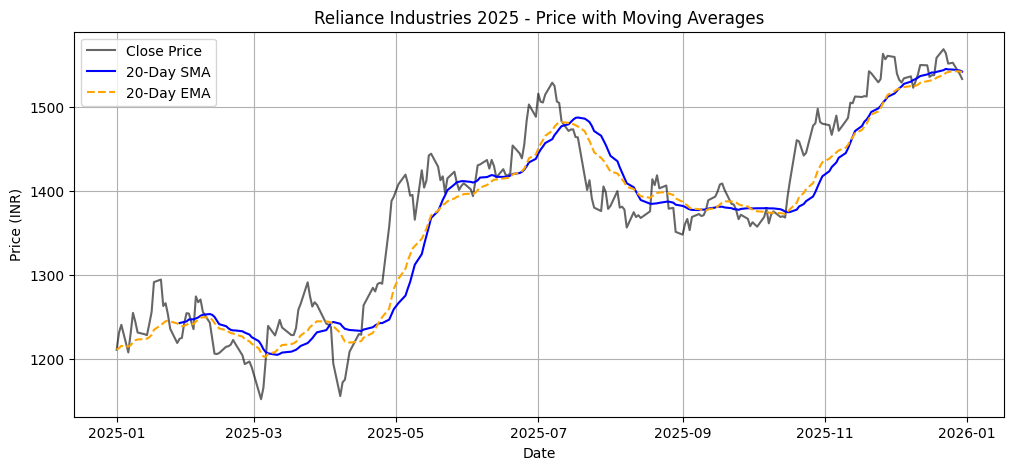

In [26]:
# Graph 1: Stock Price with SMA and EMA
plt.figure(figsize=(12, 5))
plt.plot(df['Date'], df['Close'], label='Close Price', color='black', alpha=0.6)
plt.plot(df['Date'], df['Moving_Avg'], label='20-Day SMA', color='blue')
plt.plot(df['Date'], df['EMA_20'], label='20-Day EMA', color='orange', linestyle='--')
plt.title('Reliance Industries 2025 - Price with Moving Averages')
plt.xlabel('Date')
plt.ylabel('Price (INR)')
plt.legend()
plt.grid(True)
plt.show()

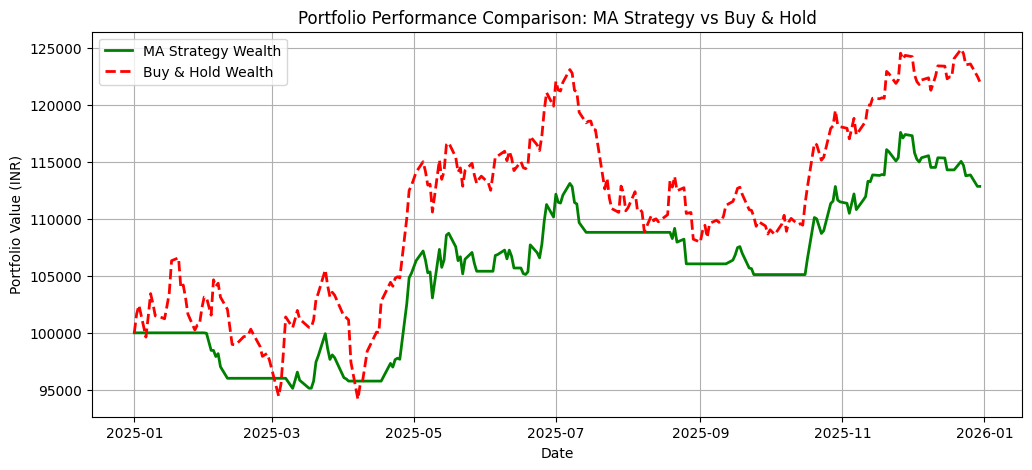

In [27]:
# Graph 2: Strategy Cumulative Wealth vs Buy & Hold Wealth
plt.figure(figsize=(12, 5))
plt.plot(df['Date'], df['Cumulative_Wealth'], label='MA Strategy Wealth', color='green', linewidth=2)
plt.plot(df['Date'], df['Buy_Hold_Wealth'], label='Buy & Hold Wealth', color='red', linestyle='--', linewidth=2)
plt.title('Portfolio Performance Comparison: MA Strategy vs Buy & Hold')
plt.xlabel('Date')
plt.ylabel('Portfolio Value (INR)')
plt.legend()
plt.grid(True)
plt.show()

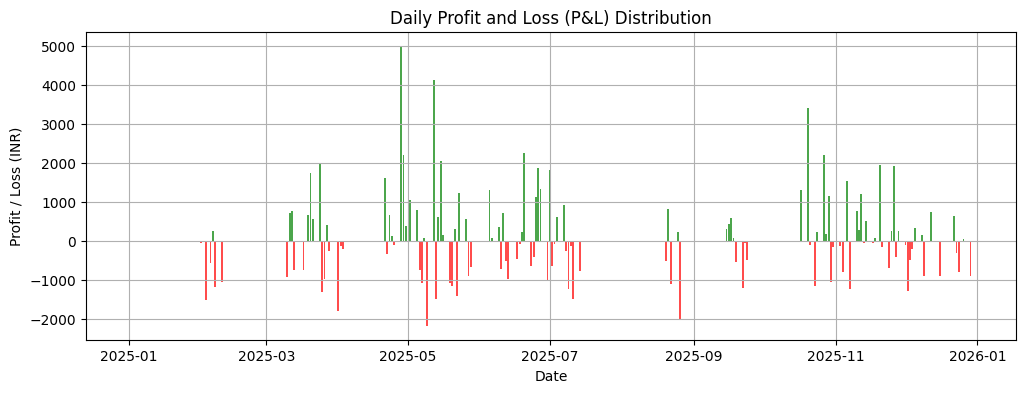

In [28]:
# Graph 3: Daily Profit/Loss Bar Chart
plt.figure(figsize=(12, 4))
plt.bar(df['Date'], df['Daily_Profit'], color=np.where(df['Daily_Profit'] >= 0, 'g', 'r'), alpha=0.7)
plt.title('Daily Profit and Loss (P&L) Distribution')
plt.xlabel('Date')
plt.ylabel('Profit / Loss (INR)')
plt.grid(True)
plt.show()